# Initial Acquisition and Equalization in OFDM

This notebook focuses on Orthogonal Frequency Division Multiplexing (OFDM). Specifically, we focus on synchronizing to the OFDM symbol structure, estimating and correcting frequency offset, and frequency domain equalization for signals received over dispersive channels.



In [1]:
## Boilerplate instructions for importing NumPy and Matplotlib
# Import NumPy
import numpy as np
import scipy as sp

from typing import Tuple

# To plot pretty figures, use matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
sns_context = "notebook"
sns.set_theme(context=sns_context, style="ticks")

## The code below imports functions defined in earlier notebooks

In [2]:
from dc_632_26.sequences import lfsr
from dc_632_26.sources import random_bit_source
from dc_632_26.demodulation import GenericSlicer
from dc_632_26.modulation import modulation
from dc_632_26.constellations import standard_constellation

## Transmitted Signal

For this notebook, we define a signalling format that is meant to resemble the downlink of  LTE and 5G NR formats. It is characterized by
* Subcarrier spacing is 15KHz
* FFT size is 2048
* Only 1272 of the subcarriers are occupied; active subcarriers are numbered from $k=0$ to $k=1271$.
* The Cyclic Prefix is 160 samples long; that corresponds to $\frac{160}{2048} \cdot \frac{1}{15\text{KHz}} = 5.2\mu s$.

Information is transmitted in slots that contain 14 OFDM symbols; the length of a slot is just under 1ms.

The first OFDM symbol in each slot contains a known synchronization reference signal. This signal occupies 127 subcarriers in the center of the active subcarriers (i.e., from $k=573$ to $k=699$).

The remaining 13 OFDM symbols contain information for three users. Eacch of the three signals occupies a different portion of the resource elements in the slot.
* user 1 occupies all 1272 active subcarriers in OFDM symbols $l=1$ to $l=4$.
* user 2 ocuppies subcarriers $k=0$ through $k=635$ in OFDM symbols $l=5$ to $l=13$
* user 3 ocuppies subcarriers $k=636$ through $k=1271$ in OFDM symbols $l=5$ to $l=13$

Each of the three signals is preceded by a demodulation reference signal (DMRS) that is located in the first allocated symbol and spans the entrire allocated bandwidth.

### Construction of a Transmitted Slot

Construction of the transmitted slot involves:
* allocating storage to hold the slot
* insertion of the synchronization reference signal
* insertion of the user data (with accompanying DMRS)
* OFDM; inverse DFT, cyclic prefix, and parallel-to-serial conversion

In [3]:
## Parameters
sc_spacing = 15e3
N_FFT = 2048
N_active = 1272
N_syms = 14
N_CP = 160

N_guard = (N_FFT - N_active) // 2

fs = sc_spacing * N_FFT

## Allocate space for a slot
Slot_active = np.zeros((N_syms, N_active), dtype=complex)

#### Synchronization Reference Signal

The synchronization reference signal is defined in the frequency domain. The resource elements holding the synchronization signal are chosen from a length 127 M-sequence. Specifically, the M-sequence generated by a linear feedback shift register with initial value $c_{init}=1$ and feedback connections described by $0x3$ is used.

In [4]:
## Generate LFSR sequence 
c_init = np.uint32(1)
fb = np.uint32(3)
M = 127
N = 7

# generate M-sequence and convert to BPSK (0 -> -1, 1 -> 1)
seq = modulation(lfsr(c_init, fb, M, N), standard_constellation.BPSK)

# insert seq into slot
Slot_active[0, 573:700] = seq

#### User signals

The signals for each of the three users consists of a training sequence DMRS that occupies the first symbol of the allocated resource elements. That is followed by the payload. We model the payload as random QPSK symbols.

**SLIV** stands for Start and Length Indicator Value; it indicates where payloads for specific users can be found.

In [5]:
## define a list of dictionaries that describes where each user's signals goes
sliv_l = [
    {'id': 1,
    'l0' : 1,    # first symbol
    'le': 4,     # last symbol
    'k0': 0,     # first subcarrier
    'ke': 1271}, # last subcarrier
    {'id': 2,
    'l0': 5,
    'le': 13,
    'k0': 0,
    'ke': 635},
    {'id': 3,
    'l0': 5,
    'le': 13,
    'k0': 636,
    'ke': 1271},
]

##### DMRS signals

 The DMRS training sequences are intended to provide initialization fot the frequency domain equalizer. We will use Gold sequences that were derived from a pair of M-sequences of order 31. 

 The DMRS sequences are initialized by the user's ID, so that the reference sequences are all distinct.

 Reference sequences are always generated to cover all sub-carriers. Only the sub-carriers in the user's active bandwidth will be transmitted.

 Only every fourth sub-carrier will be used for training. The empty sub-carriers can be used in a MIMO configuration to provide training separately for each transmit antenna.

In [6]:
## Generate the DMRS sequences for all users and insert in slot
M_dmrs = 4   # use only every fourth subcarrier

for user in sliv_l:
    id = user['id']

    # make a Gold sequence from 2 M-sequences, the second is initialized by user's id
    dmrs = (lfsr(np.uint32(1), np.uint32(9), N_active, 31, 1600) ^ 
            lfsr(np.uint32(id), np.uint32(15), N_active, 31, 1600))
    # convert binary to BPSK
    dmrs = modulation(dmrs, standard_constellation.BPSK)

    # insert dmrs in first symbol of allocated bandwidth
    l0 = user['l0']
    k0 = user['k0']
    ke = user['ke']

    all_sc = np.arange(N_active)
    use_for_dmrs = np.logical_and(np.logical_and(all_sc >= k0, all_sc <= ke), 
                                  all_sc % 4 == 2) # really?
    
    Slot_active[l0, use_for_dmrs] = dmrs[use_for_dmrs]

##### Payload

For the payoad, we insert randomly generated QPSK symbols in the allocated subcarriers.

In [7]:
pld_mod = standard_constellation.QPSK

payloads = {}     # for storing the payloads for later comparison

for user in sliv_l:
    l0 = user['l0']
    k0 = user['k0']
    ke = user['ke']
    le = user['le']

    L = le - l0
    K = ke - k0 + 1
    pld_bits = random_bit_source(pld_mod.bits_per_symbol * L*K)
    pld = modulation(pld_bits, pld_mod).reshape(L,K) 

    # place in slot
    Slot_active[l0+1:le+1, k0:ke+1] = pld
    
    # store in dict for later
    payloads[user['id']] = pld_bits



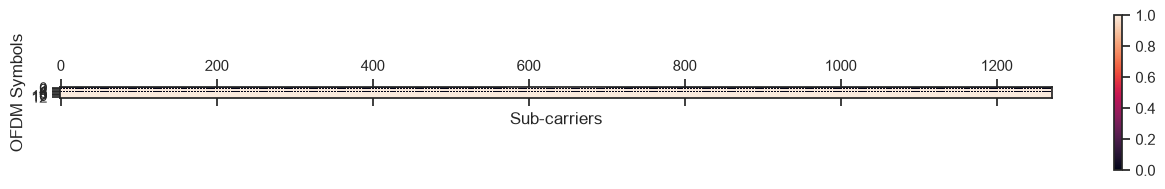

In [8]:
plt.matshow(np.abs(Slot_active))
plt.xlabel('Sub-carriers')
plt.ylabel('OFDM Symbols')
plt.colorbar()
plt.show()

#### OFDM

Now that the slot has been constructed in the frequency domain, we need to perform OFDM. This consists of
* zero-padding to the FFT size; this also adds guard bands
* inverse DFT
* insert the cyclic prefix
* P/S conversion 

In [9]:

## OFDM
# zero-pad in frequency
Slot_FD = np.zeros((N_syms, N_FFT), dtype=complex)
Slot_FD[:, N_guard:N_guard+N_active] = Slot_active

# inverse DFT (we also need to FFT shift)
Slot = np.fft.ifft(np.fft.fftshift(Slot_FD, axes=(1,))) * np.sqrt(N_FFT)

# P/S and cyclic prefix
sig = np.zeros(N_syms * (N_FFT+N_CP), dtype=complex)
for n in range(N_syms):
    start = n * (N_FFT + N_CP)
    sig[start : start+N_CP] = Slot[n, -N_CP:]
    start += N_CP
    sig[start : start+N_FFT] = Slot[n, :]

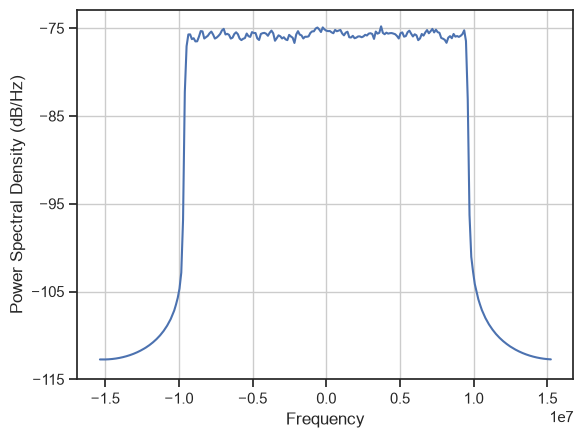

In [10]:
## check that the PSD is as expected
f,s = plt.psd(sig, Fs=fs)
plt.show()

## Channel

The channel introduces a delay, a frequency offset, and multi-path distortion.

In [69]:
## channel
# delay
delay_samples = 1025

# frequency offset
df = 1e3 / fs  # 1KHz

# delay by pre-pending zeros and apply frequency error
rr = np.concatenate(( np.zeros(delay_samples, dtype=complex), 
                      sig * np.exp(2j * np.pi * df * np.arange(len(sig))),
                      np.zeros(N_FFT, dtype=complex) ))


# dispersive channel
delay_spread = 1e-6  # 1 microsecond
ds_samples = int( delay_spread * fs )

c = np.zeros(ds_samples, dtype=complex)
c[:len(c)//2] = 0.75*np.exp(-1/2*np.arange(len(c)//2))
c[len(c)//2:] = 0.1*np.exp(-1/10*np.arange(len(c)//2))
c[:] = np.exp(-1/8*np.arange(len(c)))
c *= np.exp(2j*np.pi*np.random.rand(len(c)))
c = c / np.linalg.norm(c)

rr = np.convolve(rr, c)

# AWGN
SNR_dB = 20
SNR = 10**(SNR_dB/10)
noise_var = np.var(sig) / SNR 

# add noise 
rr = rr + np.sqrt(0.5 * noise_var) * (np.random.randn(len(rr)) + 1j*np.random.randn(len(rr))) 

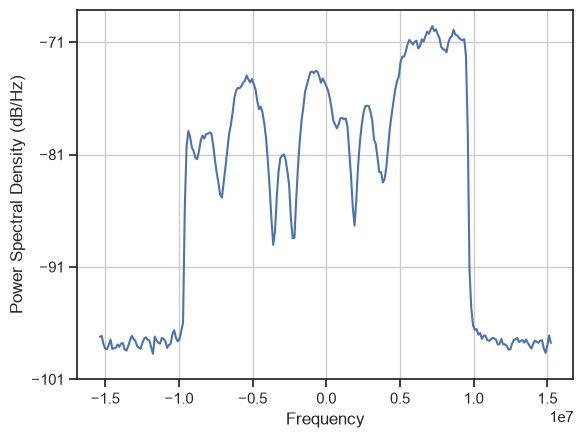

In [70]:
## check that the PSD is as expected
# we can see the squared magnitude of the frequency response
f,s = plt.psd(rr, Fs=fs)

## Receiver Processing

To recover the users' payloads successfully, we must:
* locate the slot and symbol boundaries boundaries
* estimate and compensate the frequency offset
* locate the resource elements that contain the users' data and perform frequency domain equalization

We perform these steps in the indicated order.

### Find symbol boundaries via the cyclic prefix

The cyclic prefix provides a feature that can be used to identify symbol boundaries and also to derive an estimate of the frequency error.

The cyclic prefix repeats the last $N_{CP}$ samples of an OFDM symbols before the start of the symbol. We compute the following correlation to test if the cyclic prefix starts at sample index $n$
$$
\rho[n] = \sum_{k=0}^{N_{CP}-1} r[n] \cdot r^*[n+N_{FFT}].
$$

A large absolute value of $\rho[n]$ marks the start of the preamble. Moreover. the phase of $\rho[n]$ can be used to estimate the frequency error.

As usual, it may be advantageous to use a normalized metric, e.g.,
$$
\tilde{\rho}[n] = \frac{|\sum_{k=0}^{N_{CP}-1} r[n] \cdot r^*[n+N_{FFT}]|}{\sum_{k=0}^{N_{CP}-1} |r[n]|^2}.
$$

Additionally, in highly dispersive channels it may be beneficial to truncate the summations by eliminating the first few terms that are most impacted by the switching transient between symbols.

Below, we compute the metric $\tilde{\rho[n]}$ for all samples $n$ (for which enough data are present).

In [71]:
## Compute the correlation rho for all signal samples
# 
rho = np.zeros_like(rr)

for n in range(len(rr) - N_CP - N_FFT):
    denom = np.sum( np.abs(rr[n : n+N_CP])**2 )
    rho[n] = np.sum(rr[n : n+N_CP].conj() * rr[n+N_FFT : n+N_FFT+N_CP]) / denom

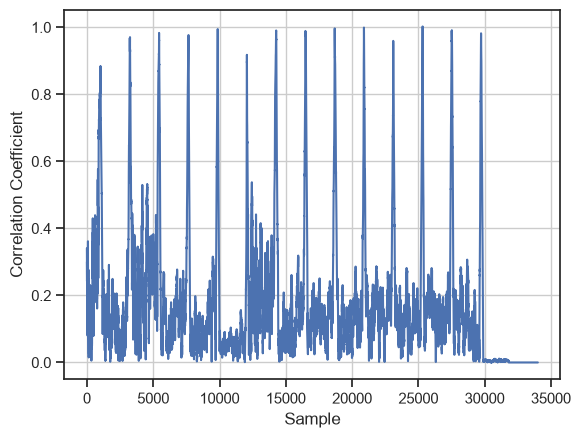

In [72]:
plt.plot(np.abs(rho))
plt.grid()
plt.xlabel("Sample")
plt.ylabel("Correlation Coefficient")

plt.show()

The normalized correlation $\tilde{\rho}[n]$ shows 14 clearly defined peaks. Each of these peaks corresponds to the start of a cyclic prefix.

Note that the regions during symbol $l=0, 2, 5$ appear noisier than the remaining symbols. This is caused by the fact that these symbols are only partially occupied.

Let's find the location of the peaks and examine their phases.

In [73]:
loc = np.zeros(N_syms, dtype=int)
corr = np.zeros(N_syms, dtype=complex)

for n in range(N_syms):
    start = delay_samples - N_FFT // 2 + n * (N_FFT + N_CP)
    end = start + N_FFT

    loc[n] = np.argmax(np.abs(rho[start:end])) + start
    corr[n] = rho[loc[n]]

We expect the difference between the locations of correlation peaks to be $N_{FFT} + N_{CP} = 2208$. Let's see if that holds.

In [74]:
## compute the difference between consecutive correlation peaks
print( np.diff(loc) )
print('Mean = ', np.mean(np.diff(loc)))

[2226 2193 2218 2204 2202 2205 2210 2209 2206 2210 2214 2208 2201]
Mean =  2208.153846153846


#### Frequency Estimation from Cyclic Prefixes

The phase difference between the cyclic prefix and the symbols at the end of the preamble is a result of frequency offset. Specifically,
the phase difference is 
$$
    \Delta \phi = 2 \pi  \frac{\Delta f}{f_s}  N_{FFT} 
$$

The phase at the locations of the correlation peaks measures this phase difference.

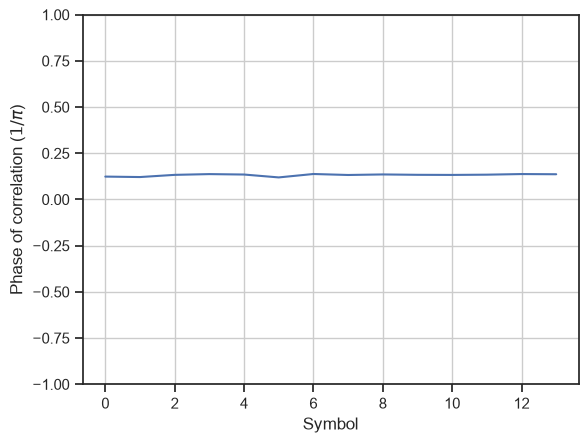

In [75]:
## plot phase of correlation peaks
plt.plot(np.angle(corr)/np.pi)
plt.grid()

plt.ylim(-1, 1)
plt.xlabel('Symbol')
plt.ylabel(r'Phase of correlation ($1/\pi$)')

plt.show()

The phase of the correlation peaks is approximately constant in each symbol period. The measured value is approximately $0.13 \pi$.

From this measurement, we can estimate the frequency offset as
$$
    \frac{2 \pi  \Delta f}{f_s} = \frac{\Delta \phi}{N_{FFT}} \quad \text{radians per sample}
$$

In absolute terms, a the measured phase difference of $0.13 \pi$ corresponds to a frequency error of 994Hz (true value is 1KHz).

We can use this estimate to initialize a frequency-locked loop and update that loop once per symbol period from a new phase measurement.

In [76]:
df_est = np.angle(np.mean(corr)) /(2*np.pi)/N_FFT
print("Estimated frequency offset: {:5.1f} Hz (True: {:5.1f} Hz)".format(df_est*fs, df*fs))

Estimated frequency offset: 992.2 Hz (True: 1000.0 Hz)


### Find slot boundaries from Synchronization reference signal

From the correlations of the cyclic prefix, we know where the symbol boundaries are. However, we must also know where the slot boundaries are since user data are arranged relative to the slot boundaries.

The synchronization reference signal provides the means to identify slot boundaries.  According to our specifications, if a symbol contains the reference signal then it must be the first symbol in the slot.

Without knowledge about the symbol boundaries, we would have to search sample by sample for the reference signal. Knowing the sybol boundaries, we only need to check if the signal that occupies the current symbol contains the reference signal.

To do so, we correlate the time-domain reference signal against the received samples in the given symbol. This provides an opportunity to search over a few samples around the assumed start of the symbol to solidify our estimate of the symbol boundary.

We begin by constructing the reference signal.

In [77]:
## First, construct the reference signal
# Generate LFSR sequence 
c_init = 1
fb = 3
M = 127
N = 7

# generate M-sequence and convert to BPSK (0 -> -1, 1 -> 1)
seq = modulation(lfsr(np.uint32(c_init), np.uint32(fb), M, N), standard_constellation.BPSK)

# construct FD reference signal
ref_active = np.zeros(N_active, dtype=complex)
ref_active[573:700] = seq
ref_fd = np.zeros(N_FFT, dtype=complex)
ref_fd[N_guard:N_guard+N_active] = ref_active

# inverse DFT to construct time-domain reference signal
ref_sig = np.fft.ifft(np.fft.fftshift(ref_fd)) * np.sqrt(N_FFT)

Now, we can correlate the reference signal against the received signals during each of the symbol periods. Obviously, we would do this only until we have found the reference signal. The other correlations are intended only to show that they don't correlate against the reference signal.

We use the estimated symbol boundaries from the cyclic prefix and search $\pm 50$ samples around these estimates for the best correlation.

Also, the correlation must be performed over the symbol itself - not the cyclic prefix.

**Note:** The computational efficiency of the correlation can be improved greatly by exploiting the fact that the reference signal is narrow-band as it occupies only 127 sub-carriers

In [78]:
## check each symbol to see if it contains the reference signal
corr_ref = np.zeros(N_syms, dtype=float)
loc_s = np.zeros(N_syms, dtype=int)

for n in range(N_syms):
    U = 50
    corrs = np.zeros(2*U, dtype=complex)

    for m in range(2*U):
        this_loc = loc[n] + N_CP + m - U
        corrs[m] = np.sum(rr[this_loc : this_loc+N_FFT] * ref_sig.conj())

    loc_s[n] = loc[n] + np.argmax(np.abs(corrs)) - U
    corr_ref[n] = np.max(np.abs(corrs))

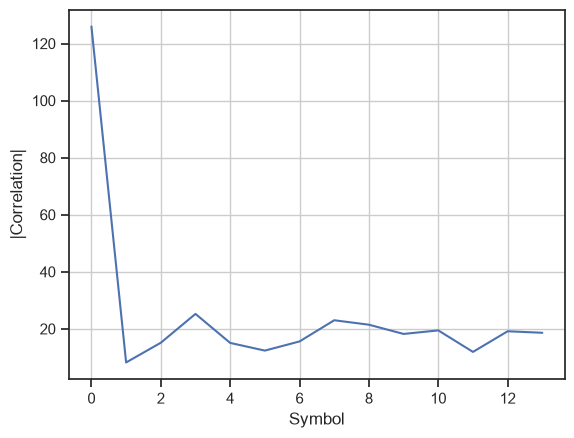

Best correlation starts at sample 1027 + N_CP


In [79]:
plt.plot(corr_ref)
plt.grid()
plt.xlabel('Symbol')
plt.ylabel('|Correlation|')

plt.show()

print("Best correlation starts at sample {:d} + N_CP".format(loc_s[0]))

### Demodulation

We have shown how the symbol and slot boundaries can be found from the synchronization reference signal and the cyclic prefix. 

Also, we have a solid estimate of the frequency error that we can use to correct the frequency error; a tracking loop is omitted here but should be included when the frequency error is time-varying.

Demodulation proceeds as follows:
* For each symbol, we extract the pertinent samples (after the cyclic prefix) and perform frequency correction
* The frequency corrected samples are then transformed to the frequency domain
* Finally, the resource elements for each user are demodulated as described in more detail below.

It is critical that the frequency correction is applied in a phase-continuous manner. 
It is not sufficient to simply multiply the samples in each symbol by $e^{-j2\pi \delta f n}$. The phase increase over the course of each symbol period must be reflected as the initial phase at the start of the next block. The phase increase in each bleck is equal to $-2\pi \delta f (N_{FFT}+N_{CP})$.

In [80]:
## transform signal to frequency domain
RX_fd = np.zeros((N_syms, N_FFT), dtype=complex)

# estimated frequency offset from above is used, we need to ensure
# that frequency correction is phase continuous
init_phase = 0

for n in range(N_syms):
    # find first sample of n-th symbol
    start = loc_s[0] + N_CP + n * (N_CP + N_FFT)

    # frequency correction - phase continuous
    this_rr = rr[start:start+N_FFT] * np.exp(-1j * (init_phase + 2*np.pi * 
                                                    df_est * np.arange(N_FFT)))
    init_phase += 2*np.pi * df_est * (N_FFT + N_CP)

    RX_fd[n, :] = np.fft.fftshift(np.fft.fft(this_rr))

RX_active = RX_fd[:, N_guard:N_guard+N_active]

#### Extract the DMRS symbols

The DMRS symbols are used to initialize the frequency domain equalizer. We extract the resource elements that hold the DMRS symbols and multiply them with the conjugate complex of the DMRS symbols.

This provides an estimate for the complex gain for the subcarrriers holding the DMRS symbols.

First, for each user we need the pertinent DMRS symbols; this is essentially a repeat of code above.

In [81]:
## Generate the DMRS sequences for all users 
M_dmrs = 4   # use only every fourth subcarrier

dmrs_seqs = {}

for user in sliv_l:
    id = user['id']

    # make a Gold sequence from 2 M-sequences, the second is initialized by user's id
    dmrs = (lfsr(np.uint32(1), np.uint32(9), N_active, 31, 1600) ^ 
            lfsr(np.uint32(id), np.uint32(15), N_active, 31, 1600))
    
    # convert binary to BPSK
    dmrs = modulation(dmrs, standard_constellation.BPSK)

    # insert dmrs in first symbol of allocated bandwidth
    l0 = user['l0']
    k0 = user['k0']
    ke = user['ke']

    all_sc = np.arange(N_active)
    use_for_dmrs = np.logical_and(np.logical_and(all_sc >= k0, all_sc <= ke), 
                                  all_sc % M_dmrs == 2) # nested logical and!

    this_dmrs = np.zeros(N_active, dtype=complex)
    this_dmrs[use_for_dmrs] = dmrs[use_for_dmrs]

    dmrs_seqs[id] = this_dmrs

#### Channel Estimation

For each subcarrier, we form an estimate of the frequency response at that subcarrier. For subcarriers that hold a DMRS symbol, we can simply divide the received symbol by the respective DMRS symbol.

Channel estimates for the subcarriers that are not measured directly by a DMRS symbol, linear interpolation is used to fill in these gaps.

The linear interpolation is performed by filtering the sequence of channel estimates (at DMRS locations) with `M_dmrs`-1 zeros in between these locations with a triangular impulse (of width `2*M_dmrs`). Care must be taken to account for the filter delay and the filter transients.

The result is an estimate of the channel response for each subcarrier that is used by the three users.

In [82]:
## Derive initial equalizer values
eqs = {}

# create a triangular pulse to be used as the interpolation filter [0, 1/M, ..., 1, 1-1/M, ..., 1/M]
# by including the leading zero, the filter delay is M_dmrs
intp_filter = np.concatenate((np.arange(M_dmrs+1)/M_dmrs, 1 - np.arange(1, M_dmrs)/M_dmrs))

for user in sliv_l:
    id = user['id']
    l0 = user['l0']
    k0 = user['k0']
    ke = user['ke']

    # pull out the symbol that holds the DMRS
    rx_dmrs = RX_active[l0,:]
    this_dmrs = dmrs_seqs[id]

    # allocate space for equalizer and initialize to zeros
    this_eq = np.zeros_like(this_dmrs)

    # at the DMRS locations, equalizer weights can be computed directly
    # estimate the channel at the locations of the DMRS subcarriers,
    # in between the DMRS locations, there are zeros
    for  k in range(k0, ke+1):
        if k % M_dmrs == 2:   #  is this a DMRS subcarrier?
            this_eq[k] = rx_dmrs[k] / this_dmrs[k]

    # perform linear interpolation by filtering with above filter
    tmp = np.convolve(this_eq, intp_filter)

    # after filtering, remove filter delay and trim transient at end
    eqs[id] = tmp[M_dmrs:M_dmrs+len(this_eq)]
   

To verify that this worked, we can plot the interpolated frequency response as well as the measured frequency response at the DMRS locations. Specifically, we plot the phase of the estimate.

If everything worked correctly, we should see a fairly continuous phase reponse and the DMRS measurements should lie on the interpolated phase response.

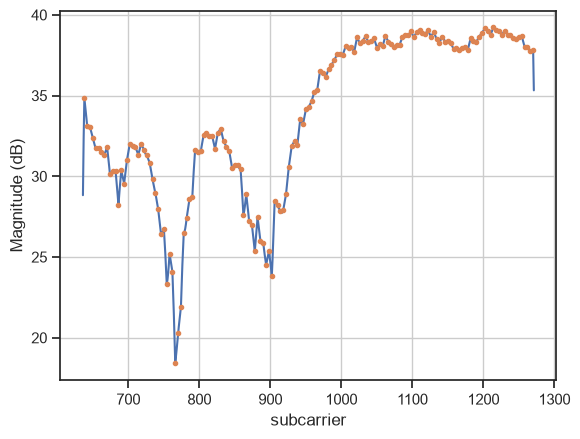

In [83]:
## plot magnitude of estimated frequency response - for last user (id = 2)
plt.plot(np.arange(k0, ke+1), (20*np.log10(np.abs(eqs[id][k0:ke+1]))))       # interpolated
plt.plot(np.arange(N_active)[use_for_dmrs],20*np.log10(np.abs(this_eq[use_for_dmrs])),'.')   # measured or zero

plt.grid()
plt.xlabel('subcarrier')
plt.ylabel('Magnitude (dB)')

plt.show()

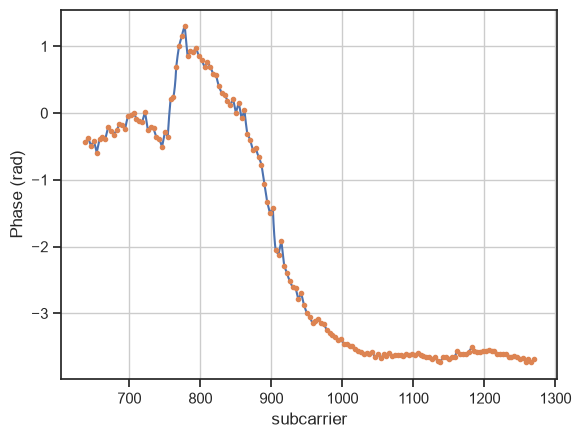

In [84]:
## plot phase of estimated frequency response
plt.plot(np.arange(k0, ke+1),np.unwrap(np.angle(eqs[id][k0:ke+1])))       # interpolated
plt.plot(np.arange(N_active)[use_for_dmrs],np.unwrap(np.angle(this_eq[use_for_dmrs])),'.')   # measured or zero

plt.grid()
plt.xlabel('subcarrier')
plt.ylabel('Phase (rad)')

plt.show()

Additionally, we verify that the three channel estimates (for each user) are consistent. This verifies mainly that we have successfully mitigated the frequency offset.

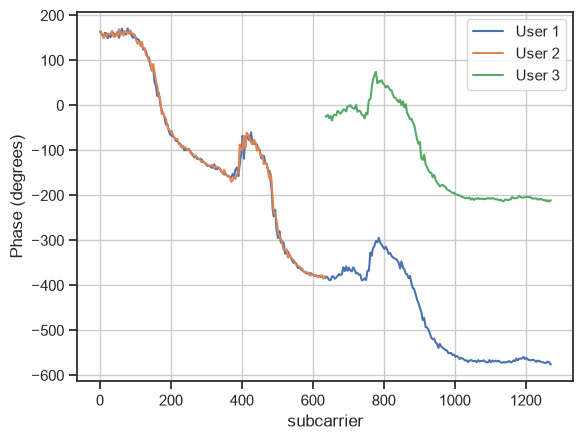

In [85]:
for user in sliv_l:
    id = user['id']
    k0 = user['k0']
    ke = user['ke']
    plt.plot(np.arange(k0, ke+1), 
        np.unwrap(np.angle(eqs[id][k0:ke+1]))*180/np.pi, 
        label='User {:d}'.format(id))

plt.grid()
plt.legend()
plt.xlabel('subcarrier')
plt.ylabel('Phase (degrees)')

plt.show()

#### Demodulation

We are now in position to perform demodulation. 

We can isolate the resource elements that hold user symbols based on the information in the SLIV dictionary. 

These samples are still affected by the frequency response of the channel. We use the channel estimates to compensate for the frequency response. This amounts to simply dividing the received frequency domain samples by the channel estimates for the appropriate subcarrier. This is called *frequency domain equalization*.

User 1: 5 errors in 7632 bits
User 2: 4 errors in 10176 bits
User 3: 0 errors in 10176 bits


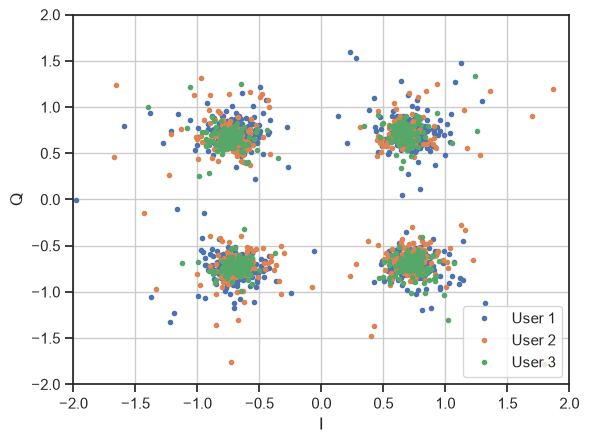

In [88]:
slicer = GenericSlicer(pld_mod)

for user in sliv_l:
    id = user['id']
    l0 = user['l0']
    k0 = user['k0']
    ke = user['ke']
    le = user['le']

    L = le - l0
    K = ke - k0 + 1
    pld_est = np.zeros(pld_mod.bits_per_symbol * L*K, dtype=complex).reshape(L,pld_mod.bits_per_symbol*K) 

    # process each occupied symbol
    n = 0
    for l in range(l0+1, le+1):
        # frequency domain equalizer
        rx_eq = RX_active[l,k0:ke+1] / eqs[id][k0:ke+1]
        
        # decision
        pld_est[n, :] = slicer.slice_symbols(rx_eq) #MPE_decision_rule(rx_eq, A)
        
        # could update channel estimates based on difference between rx_eq and pld_est 

        n += 1

    print("User {:d}: {:d} errors in {:d} bits".format(id, np.sum(pld_est.reshape(-1) != payloads[id]), L*K*pld_mod.bits_per_symbol))

    plt.plot(rx_eq.real, rx_eq.imag, '.', label=f'User {id}')
    
plt.grid()
#plt.axis('equal')
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.xlabel('I')
plt.ylabel('Q')
plt.legend()

plt.show()
    